# Notebook 2: Thử Nghiệm Mô Hình & So Sánh Hiệu Năng
## Sequence-to-Sequence Weather Forecasting (Topic 5)

Notebook này minh họa quy trình:
1. Khởi tạo 3 kiến trúc mô hình: **Baseline Seq2Seq LSTM**, **Seq2Seq Attention LSTM**, và **TimeSeries Transformer**.
2. Đo đạc tốc độ suy luận (Latency theo mili-giây) và tài nguyên RAM / VRAM.
3. Trực quan hóa dự báo nhiệt độ 72 giờ (3 ngày) tiếp theo.
4. Hiển thị ma trận nhiệt **Attention Heatmap** để giải thích mô hình (Explainable AI).

In [1]:
import os
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml

from src.data_module import JenaDataModule
from src.model_builder import build_model
from src.evaluation import ModelEvaluator

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Thiết bị tính toán: {device}")

Thiết bị tính toán: cuda


### 1. Nạp Cấu Hình Dự Án

In [2]:
with open('../configs/config.yaml', 'r', encoding='utf-8') as f:
    config = yaml.safe_load(f)

print(f"Dự án: {config['project']['name']}")
print(f"Cửa sổ: {config['data']['seq_len']}h quá khứ -> {config['data']['pred_len']}h tương lai.")

Dự án: course_work_topic_5_LSTM_regression_jena_climate_dataset
Cửa sổ: 168h quá khứ -> 72h tương lai.


### 2. Khởi Tạo 3 Mô Hình Học Sâu

In [3]:
model_baseline = build_model('seq2seq_lstm', config).to(device)
model_attention = build_model('seq2seq_attention', config).to(device)
model_transformer = build_model('transformer', config).to(device)

print("Đã khởi tạo thành công cả 3 mô hình!")

Đã khởi tạo thành công cả 3 mô hình!


### 3. Kiểm Thử Lan Truyền Tiến (Forward Pass) & So Sánh Kích Thước Tensor

In [4]:
# Tạo một batch kiểm thử (Batch_size=4, Seq_len=168, Features=14)
dummy_x = torch.randn(4, 168, 14, device=device)

with torch.no_grad():
    p_base, a_base = model_baseline(dummy_x)
    p_attn, a_attn = model_attention(dummy_x)
    p_trans, a_trans = model_transformer(dummy_x)

print(f"Model 1 (Baseline):    Output shape = {p_base.shape} | Attn = {a_base}")
print(f"Model 2 (Attention):   Output shape = {p_attn.shape} | Attn shape = {a_attn.shape}")
print(f"Model 3 (Transformer): Output shape = {p_trans.shape} | Attn shape = {a_trans.shape}")

Model 1 (Baseline):    Output shape = torch.Size([4, 72, 1]) | Attn = None
Model 2 (Attention):   Output shape = torch.Size([4, 72, 1]) | Attn shape = torch.Size([4, 72, 168])
Model 3 (Transformer): Output shape = torch.Size([4, 72, 1]) | Attn shape = torch.Size([4, 72, 168])


### 4. Đo Tốc Độ Suy Luận (Latency ms) & Tiêu Thụ Bộ Nhớ

In [5]:
evaluator = ModelEvaluator(model=model_attention, device=device, results_dir='../evalution_results')
perf_results = evaluator.measure_latency_and_resources(dummy_x, num_runs=30, warmup=5)

for k, v in perf_results.items():
    print(f"{k}: {v}")

Latency_ms_per_batch: 26.66
Latency_ms_per_sample: 6.6653
RAM_MB: 1200.71
VRAM_MB: 4.91


### 5. Trực Quan Hóa Ma Trận Attention Heatmap

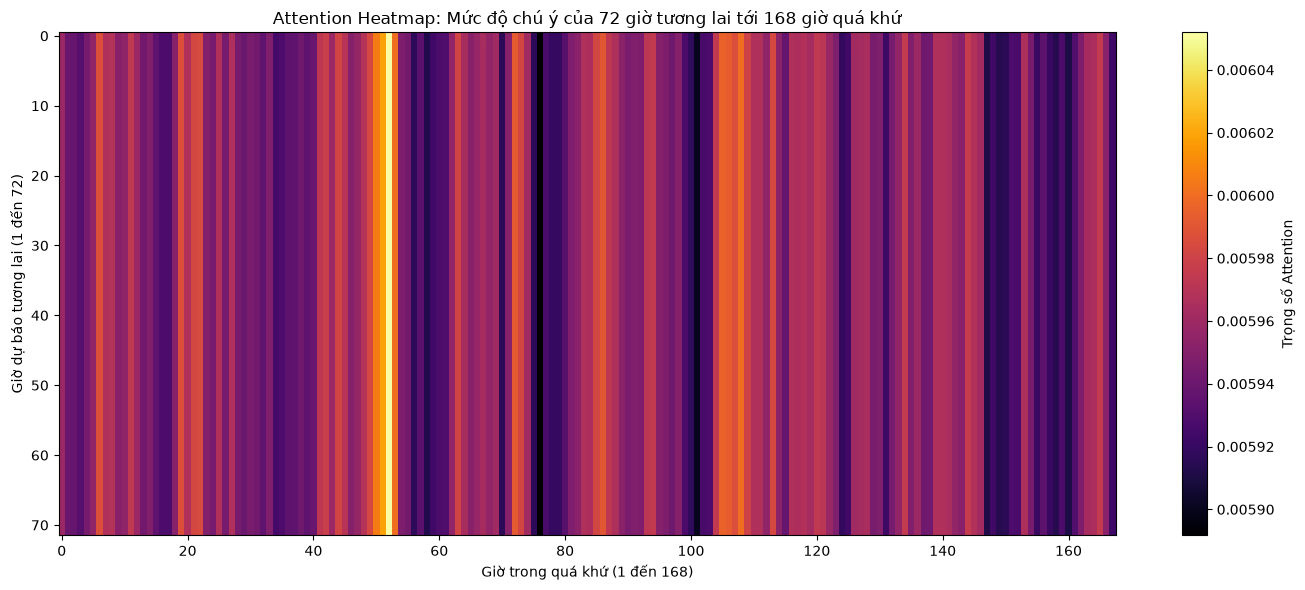

In [6]:
if a_attn is not None:
    attn_map = a_attn[0].cpu().numpy()  # shape: (72, 168)
    
    plt.figure(figsize=(14, 6))
    plt.imshow(attn_map, aspect='auto', cmap='inferno')
    plt.colorbar(label='Trọng số Attention')
    plt.title('Attention Heatmap: Mức độ chú ý của 72 giờ tương lai tới 168 giờ quá khứ')
    plt.xlabel('Giờ trong quá khứ (1 đến 168)')
    plt.ylabel('Giờ dự báo tương lai (1 đến 72)')
    plt.tight_layout()
    plt.show()